# 02 EDA — Exploratory Feature Analysis (train split only)

對應 paper **§4 Exploratory Feature Analysis**（10 分）。

**規則：只用 `split == "train"`**，val / test 完全不看（作業規定）。

本 notebook 做的事：
1. 在 train 上計算每片晶圓的簡單特徵（fail rate、外圈 / 中心 fail rate）
2. **Fig 1** normal vs defect 的 fail rate 分布對比
3. **Fig 2** 各類 defect 的 fail rate boxplot
4. **Table 1** 各類 defect 與 normal 的分離度（KS、Wasserstein、單特徵 AUROC）
5. **Fig 3** 各類別的平均 fail 空間分布圖（看出「空間 pattern」）
6. **Table 2** 特徵之間的相關性（冗餘檢查）
7. 寫下假設 H1、H2…，留到 §7–§8 驗證

輸出：圖存到 `figures/eda/`，表存到 `results/eda/`。

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, wasserstein_distance
from sklearn.metrics import roc_auc_score

ROOT = Path("..")
DATA_PATH = ROOT / "data" / "LSWMD_clean.pkl"
SPLIT_PATH = ROOT / "splits" / "split_v1.csv"
FIG_DIR = ROOT / "figures" / "eda"
RES_DIR = ROOT / "results" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

# Plot style: normal = blue, defect = orange (colorblind-safe pair)
C_NORMAL, C_DEFECT = "#2a78d6", "#eb6834"
C_TEXT, C_MUTED, C_GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": C_MUTED,
    "axes.labelcolor": C_TEXT,
    "xtick.color": C_MUTED,
    "ytick.color": C_MUTED,
    "axes.grid": True,
    "grid.color": C_GRID,
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
})

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", bbox_inches="tight")
    print("saved", FIG_DIR / f"{name}.png")

## 1. 載入資料，只取 train

In [2]:
%%time
df = pd.read_pickle(DATA_PATH)
split = pd.read_csv(SPLIT_PATH, index_col="index")

train_idx = split.index[split["split"] == "train"]
train = df.loc[train_idx, ["waferMap", "dieSize", "lotName", "failureType"]].join(split.loc[train_idx, ["label"]])
del df  # free memory; val/test are never touched in this notebook

assert set(split.loc[train.index, "split"]) == {"train"}
print(f"train wafers: {len(train):,} | normal: {(train.label == 0).sum():,} | defect: {(train.label == 1).sum():,}")

train wafers: 103,312 | normal: 87,970 | defect: 15,342
CPU times: total: 31.7 s
Wall time: 33.7 s


## 2. 特徵計算

每片晶圓計算：

| 特徵 | 定義 | 想看什麼 |
|---|---|---|
| `fail_rate` | 不良 die 數 / die 總數 | 整體壞多少（Tier 1 用的特徵） |
| `edge_fail_rate` | 外圈（正規化半徑 r > 0.8）的 fail rate | Edge-Ring / Edge-Loc |
| `center_fail_rate` | 中心（r < 0.3）的 fail rate | Center / Donut |
| `dieSize` | die 總數 | 產品差異，檢查是否與 defect 有關 |

正規化半徑 r：以所有 die（值 > 0）的幾何中心為圓心，到最遠 die 的距離為 1。

In [3]:
%%time
def wafer_features(m):
    die = m > 0
    fail = m == 2
    n_die = die.sum()
    ys, xs = np.nonzero(die)
    cy, cx = ys.mean(), xs.mean()
    yy, xx = np.indices(m.shape)
    r = np.hypot(yy - cy, xx - cx)
    r = r / r[die].max()
    edge, center = die & (r > 0.8), die & (r < 0.3)
    return (
        fail.sum() / n_die,
        fail[edge].sum() / max(edge.sum(), 1),
        fail[center].sum() / max(center.sum(), 1),
    )

feats = np.array([wafer_features(m) for m in train["waferMap"]])
train["fail_rate"], train["edge_fail_rate"], train["center_fail_rate"] = feats.T

FEATURES = ["fail_rate", "edge_fail_rate", "center_fail_rate", "dieSize"]
train[FEATURES].describe().round(3)

CPU times: total: 31 s
Wall time: 32.1 s


,fail_rate,edge_fail_rate,center_fail_rate,dieSize
count,103312.000,103312.000,103312.000,103312.000
mean,0.117,0.179,0.115,1044.746
std,0.074,0.098,0.118,1039.194
min,0.000,0.000,0.000,3.000
25%,0.068,0.111,0.050,533.000
50%,0.105,0.167,0.086,793.000
75%,0.150,0.229,0.143,1233.000
max,1.000,1.000,1.000,22372.000


In [4]:
# Class order used in every figure/table: normal first, then defects by median fail rate
DEFECTS = (train[train.label == 1].groupby("failureType")["fail_rate"].median().sort_values().index.tolist())
ORDER = ["none"] + DEFECTS
train.groupby("failureType")[FEATURES].median().loc[ORDER].round(3)

,fail_rate,edge_fail_rate,center_fail_rate,dieSize
failureType,,,,
none,0.098,0.157,0.086,776.0
Scratch,0.094,0.137,0.075,1129.0
Edge-Ring,0.138,0.320,0.054,2085.0
Loc,0.141,0.174,0.116,939.0
Edge-Loc,0.153,0.278,0.100,939.0
Center,0.254,0.282,0.583,515.0
Donut,0.262,0.159,0.215,1334.0
Random,0.478,0.512,0.486,1080.0
Near-full,0.889,0.895,0.948,741.0


## 3. Fig 1 — Normal vs Defect 的 fail rate 分布

**必要項**：至少一張 normal vs abnormal 的分布對比圖。用 density（面積 = 1），因為 normal 筆數是 defect 的 5.7 倍，用次數畫的話 defect 會被壓扁。

saved ..\figures\eda\fig1_failrate_normal_vs_defect.png


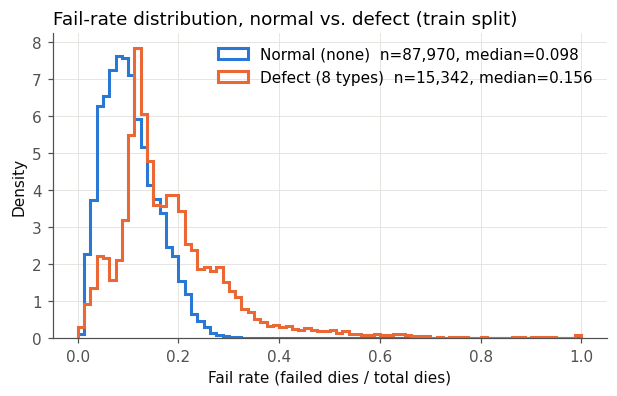

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
bins = np.linspace(0, 1, 81)
for lab, name, color in [(0, "Normal (none)", C_NORMAL), (1, "Defect (8 types)", C_DEFECT)]:
    x = train.loc[train.label == lab, "fail_rate"]
    ax.hist(x, bins=bins, density=True, histtype="step", linewidth=2, color=color,
            label=f"{name}  n={len(x):,}, median={x.median():.3f}")
ax.set_xlabel("Fail rate (failed dies / total dies)")
ax.set_ylabel("Density")
ax.set_title("Fail-rate distribution, normal vs. defect (train split)", loc="left")
ax.legend(frameon=False)
save(fig, "fig1_failrate_normal_vs_defect")
plt.show()

## 4. Fig 2 — 各類別的 fail rate

看哪些 defect 類型光靠 fail rate 就能和 normal 分開、哪些完全重疊。灰色帶 = normal 的 IQR（25–75 百分位）。

saved ..\figures\eda\fig2_failrate_by_type.png


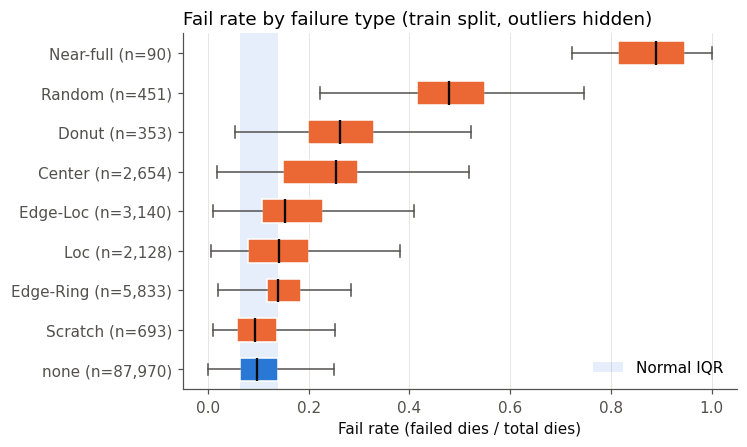

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
data = [train.loc[train.failureType == t, "fail_rate"] for t in ORDER]
q1, q3 = data[0].quantile([0.25, 0.75])
ax.axvspan(q1, q3, color=C_NORMAL, alpha=0.12, linewidth=0, label="Normal IQR")
bp = ax.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False,
                medianprops=dict(color=C_TEXT, linewidth=1.5),
                whiskerprops=dict(color=C_MUTED), capprops=dict(color=C_MUTED))
for patch, t in zip(bp["boxes"], ORDER):
    patch.set_facecolor(C_NORMAL if t == "none" else C_DEFECT)
    patch.set_edgecolor("white")
ax.set_yticks(range(1, len(ORDER) + 1))
ax.set_yticklabels([f"{t} (n={len(d):,})" for t, d in zip(ORDER, data)])
ax.set_xlabel("Fail rate (failed dies / total dies)")
ax.set_title("Fail rate by failure type (train split, outliers hidden)", loc="left")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
save(fig, "fig2_failrate_by_type")
plt.show()

## 5. Table 1 — 分離度量化

每一類 defect 都和 normal 比較，三個特徵各算：
- **KS**：兩個分布的最大 CDF 差距（0 = 完全相同，1 = 完全分開）
- **W1**：Wasserstein 距離（分布要「搬多遠」才會一樣，單位與特徵相同）
- **AUROC**：只用這一個特徵當 anomaly score 的 ROC-AUC（0.5 = 隨機；< 0.5 代表方向相反，例如 defect 的值反而比較低）

AUROC 就是「Tier 1 如果用這個特徵，最多能做到多好」的預覽（但這裡是 train，正式數字以 test 為準）。

In [7]:
rows = []
normal = train[train.label == 0]
for t in DEFECTS + ["ALL defects"]:
    d = train[train.label == 1] if t == "ALL defects" else train[train.failureType == t]
    row = {"failureType": t, "n": len(d)}
    for f in ["fail_rate", "edge_fail_rate", "center_fail_rate"]:
        a, b = normal[f].values, d[f].values
        y = np.r_[np.zeros(len(a)), np.ones(len(b))]
        row[f"{f}|KS"] = ks_2samp(a, b).statistic
        row[f"{f}|W1"] = wasserstein_distance(a, b)
        row[f"{f}|AUROC"] = roc_auc_score(y, np.r_[a, b])
    rows.append(row)

sep = pd.DataFrame(rows).set_index("failureType")
sep.to_csv(RES_DIR / "table1_separability.csv", float_format="%.4f")
sep.round(3)

,n,fail_rate|KS,fail_rate|W1,fail_rate|AUROC,edge_fail_rate|KS,edge_fail_rate|W1,edge_fail_rate|AUROC,center_fail_rate|KS,center_fail_rate|W1,center_fail_rate|AUROC
failureType,,,,,,,,,,
Scratch,693,0.051,0.006,0.481,0.117,0.014,0.447,0.090,0.011,0.465
Edge-Ring,5833,0.427,0.044,0.733,0.775,0.183,0.933,0.246,0.030,0.357
Loc,2128,0.262,0.048,0.636,0.121,0.024,0.543,0.216,0.078,0.584
Edge-Loc,3140,0.331,0.078,0.741,0.513,0.140,0.833,0.112,0.032,0.570
Center,2654,0.626,0.128,0.849,0.480,0.100,0.762,0.795,0.455,0.954
Donut,353,0.756,0.176,0.950,0.125,0.021,0.553,0.448,0.162,0.765
Random,451,0.982,0.377,0.999,0.911,0.359,0.988,0.936,0.402,0.993
Near-full,90,1.000,0.781,1.000,1.000,0.708,1.000,1.000,0.804,1.000
ALL defects,15342,0.367,0.081,0.744,0.520,0.132,0.800,0.219,0.106,0.572


In [8]:
# Compact view: AUROC only, highlighting the best feature per type
auroc = sep[[c for c in sep.columns if c.endswith("|AUROC")]].copy()
auroc.columns = [c.split("|")[0] for c in auroc.columns]
auroc["best_feature"] = auroc.idxmax(axis=1)
auroc.round(3)

,fail_rate,edge_fail_rate,center_fail_rate,best_feature
failureType,,,,
Scratch,0.481,0.447,0.465,fail_rate
Edge-Ring,0.733,0.933,0.357,edge_fail_rate
Loc,0.636,0.543,0.584,fail_rate
Edge-Loc,0.741,0.833,0.570,edge_fail_rate
Center,0.849,0.762,0.954,center_fail_rate
Donut,0.950,0.553,0.765,fail_rate
Random,0.999,0.988,0.993,fail_rate
Near-full,1.000,1.000,1.000,fail_rate
ALL defects,0.744,0.800,0.572,edge_fail_rate


## 6. Fig 3 — 各類別的平均 fail 空間分布

把每張 wafer map 用 **nearest-neighbor** 縮放到 64×64（像素值是類別，不能用 bilinear），取 `== 2`（fail）的二值圖後，每一類取平均。顏色越深 = 該位置越常壞。

這張圖直接說明「anomaly 是空間 pattern」：normal 是均勻的淡色，各 defect 有明顯不同的位置。

saved ..\figures\eda\fig3_mean_fail_map_by_type.png


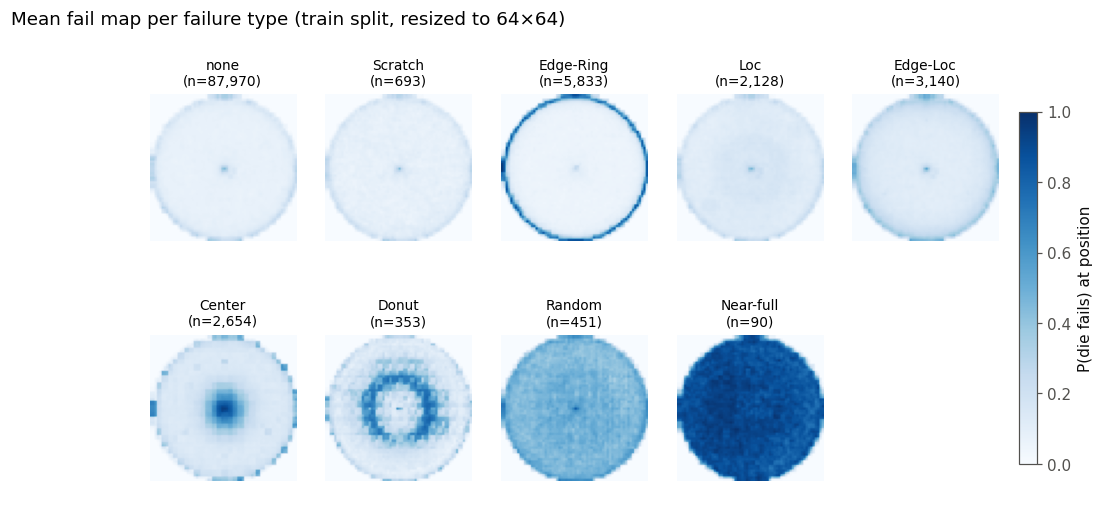

CPU times: total: 6.34 s
Wall time: 6.54 s


In [9]:
%%time
SIZE = 64
MAX_PER_CLASS = 3000  # enough for a stable mean; keeps it fast

def resize_nearest(m, size=SIZE):
    h, w = m.shape
    rows = (np.arange(size) * h / size).astype(int)
    cols = (np.arange(size) * w / size).astype(int)
    return m[np.ix_(rows, cols)]

mean_maps = {}
for t in ORDER:
    maps = train.loc[train.failureType == t, "waferMap"]
    maps = maps.sample(min(len(maps), MAX_PER_CLASS), random_state=0)
    mean_maps[t] = np.mean([resize_nearest(m) == 2 for m in maps], axis=0)

fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for ax, t in zip(axes.ravel(), ORDER):
    im = ax.imshow(mean_maps[t], cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{t}\n(n={(train.failureType == t).sum():,})", fontsize=9)
    ax.axis("off")
axes.ravel()[-1].axis("off")
cbar = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02)
cbar.set_label("P(die fails) at position")
fig.suptitle("Mean fail map per failure type (train split, resized to 64×64)", x=0.02, ha="left")
save(fig, "fig3_mean_fail_map_by_type")
plt.show()

## 7. Table 2 — 特徵冗餘檢查

Spearman 相關係數（對排名做相關，不受極端值影響）。|ρ| > 0.8 代表兩個特徵幾乎在講同一件事。

In [10]:
corr = train[FEATURES].corr(method="spearman")
corr.to_csv(RES_DIR / "table2_feature_corr.csv", float_format="%.4f")
corr.round(3)

,fail_rate,edge_fail_rate,center_fail_rate,dieSize
fail_rate,1.000,0.912,0.779,-0.570
edge_fail_rate,0.912,1.000,0.600,-0.457
center_fail_rate,0.779,0.600,1.000,-0.578
dieSize,-0.570,-0.457,-0.578,1.000


In [11]:
# dieSize vs defect: is product (die size) itself associated with defects?
train["dieSize_bin"] = pd.qcut(train["dieSize"], 5)
train.groupby("dieSize_bin", observed=True)["label"].agg(["count", "mean"]).rename(columns={"mean": "defect_rate"}).round(3)

,count,defect_rate
dieSize_bin,,
"(2.999, 533.0]",28476,0.092
"(533.0, 741.0]",15899,0.088
"(741.0, 1060.0]",19776,0.105
"(1060.0, 1376.0]",20622,0.175
"(1376.0, 22372.0]",18539,0.304


## 8. 假設（Hypotheses）

以下根據驗證執行時的數字撰寫（train split）；你重跑後數字應相同，若不同請修改。這些假設要在 paper §7–§8 回頭驗證。

- **H1（fail rate 不足）**：單一 fail rate 特徵能偵測 *Near-full / Random / Donut*（AUROC ≥ 0.95），但對 *Scratch*（0.48，接近隨機）、*Loc*（0.64）、*Edge-Ring*（0.73）效果差；整體 AUROC 0.74。→ 用 Tier 1 的 per-type recall 在 test 上驗證。
- **H2（位置資訊有幫助）**：加入位置後，*Edge-Ring* 的 AUROC 從 0.73 升到 0.93（`edge_fail_rate`），*Center* 從 0.85 升到 0.95（`center_fail_rate`）；Fig 3 也顯示各類別在不同位置聚集。→ 預期 Tier 2/3（看整張圖）在這些類別明顯勝過 Tier 1。
- **H3（Scratch 最難）**：Scratch 在三個簡單特徵上都和 normal 重疊（AUROC 0.45–0.48），平均圖（Fig 3）也看不出結構，因為刮痕位置與方向不固定，取平均會被抹平。→ 預期 Scratch（和 Loc）會是 §8 false negative 的主要來源。
- **H4（dieSize 是潛在捷徑）**：defect 比例隨 dieSize 上升（最小 1/5 組 9.2% → 最大 1/5 組 30.4%）。模型可能學到「產品種類」而不是 defect pattern；若 Tier 3 用到 dieSize 類資訊需注意，或作為 §8 錯誤分析的切入點。
- **冗餘**：`fail_rate` 與 `edge_fail_rate` 的 Spearman ρ = 0.91，高度冗餘；`center_fail_rate` 與 `fail_rate` 為 0.78。